In [1]:
import pandas as pd
import joblib

# Load the trained model
model = joblib.load('best_boston_model.joblib')

print("Model loaded successfully!")

Model loaded successfully!


In [2]:
# Load the Boston Housing dataset
df = pd.read_csv('boston_data.csv')

# Display first five rows
df.head()

,ID,indus,chas,nox,rm,age,dis,rad,tax,ptratio,lstat,medv
0,1,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,4.98,24.0
1,2,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,9.14,21.6
2,4,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,2.94,33.4
3,5,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,5.33,36.2
4,7,7.87,0,0.524,6.012,66.6,5.5605,5,311,15.2,12.43,22.9


In [3]:
# Separate input features and target variable
X = df.drop(columns=['ID', 'medv'])
y = df['medv']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (333, 10)
Target shape: (333,)


In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (266, 10)
Testing data: (67, 10)


In [5]:
# Select one house from the testing data
sample_house = X_test.iloc[[0]]

# Get its actual price
actual_price = y_test.iloc[0]

print("House details:")
display(sample_house)

print("Actual House Price:", actual_price)

House details:


,indus,chas,nox,rm,age,dis,rad,tax,ptratio,lstat
25,6.91,0,0.448,6.211,6.5,5.7209,3,233,17.9,7.44


Actual House Price: 24.7


In [6]:
# Predict the house price
predicted_price = model.predict(sample_house)

print("Predicted House Price:", predicted_price[0])
print("Actual House Price:", actual_price)

Predicted House Price: 23.54569761897714
Actual House Price: 24.7


In [7]:
# Calculate prediction error
error = abs(actual_price - predicted_price[0])

print("Prediction Error:", error)

Prediction Error: 1.154302381022859


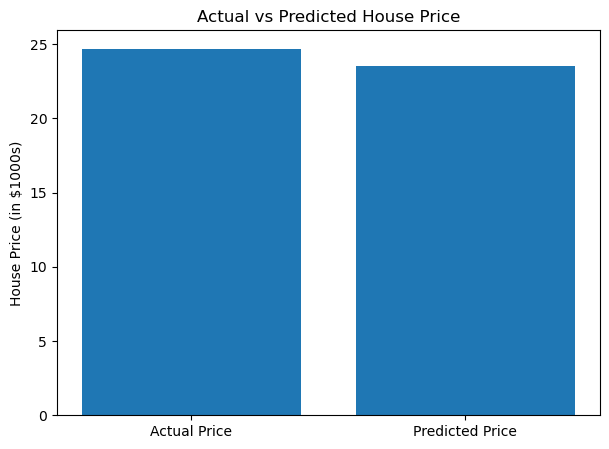

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.bar(
    ["Actual Price", "Predicted Price"],
    [actual_price, predicted_price[0]]
)

plt.title("Actual vs Predicted House Price")
plt.ylabel("House Price (in $1000s)")
plt.show()

In [9]:
# Predict prices for all testing houses
y_pred = model.predict(X_test)

# Compare actual and predicted prices
comparison = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred
})

display(comparison.head(10))

,Actual Price,Predicted Price
0,24.7,23.545698
1,19.6,19.738431
2,19.8,19.276766
3,27.9,27.613018
4,23.9,21.934312
5,13.5,16.501200
6,11.7,17.900142
7,30.7,25.857748
8,17.8,17.427524
9,27.1,24.630916


# ACCURACY= 92.65%